In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/bilalahmad302/titanic-machine-learning-from-disaster-eda/train.csv
/kaggle/input/datasets/bilalahmad302/titanic-machine-learning-from-disaster-eda/test.csv
/kaggle/input/datasets/bilalahmad302/titanic-machine-learning-from-disaster-eda/gender_submission.csv


**1. Dataset Introduction**
The Titanic dataset contains information about passengers who travelled on the Titanic ship. It includes passenger age, sex, ticket class, fare, family information, and survival status.

**Dataset source:** Kaggle Titanic Dataset

**Problem statement:** The purpose of this analysis is to explore passenger characteristics and identify patterns related to survival.

**Target variable:** Survived

0 = Did not survive

1 = Survived

The dataset will be explored using statistical summaries and visualizations to understand distributions, relationships, correlations, and unusual observations.




In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Load the Titanic training dataset
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if "train.csv" in files:
        file_path = os.path.join(root, "train.csv")
        break
else:
    raise FileNotFoundError(
        "train.csv not found. Please add the Titanic dataset."
    )

df = pd.read_csv(file_path)

# Display the first five rows
display(df.head())


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:

# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null values
print("\nDataset information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Numerical summary
print("\nStatistical summary:")
display(df.describe())


Dataset shape: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values:
PassengerId      0
Survived         0
Pclass    

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


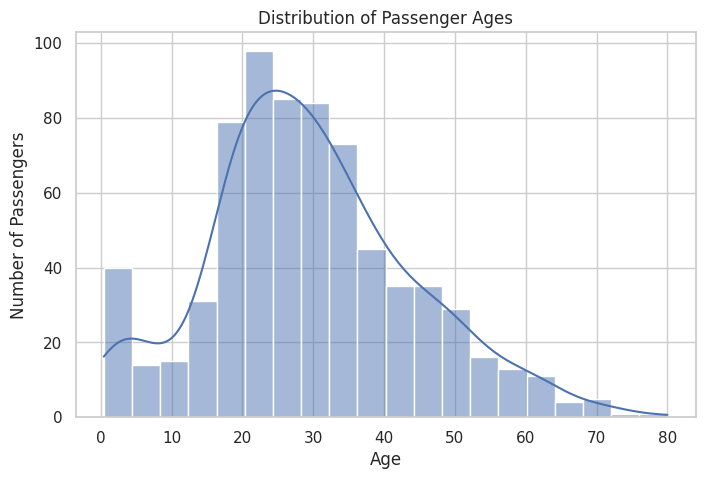

In [4]:

plt.figure(figsize=(8, 5))
sns.histplot(df["Age"].dropna(), bins=20, kde=True)
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()


The histogram shows the distribution of passenger ages. The tallest bars indicate the most common age ranges. The density curve helps show the overall shape of the distribution.

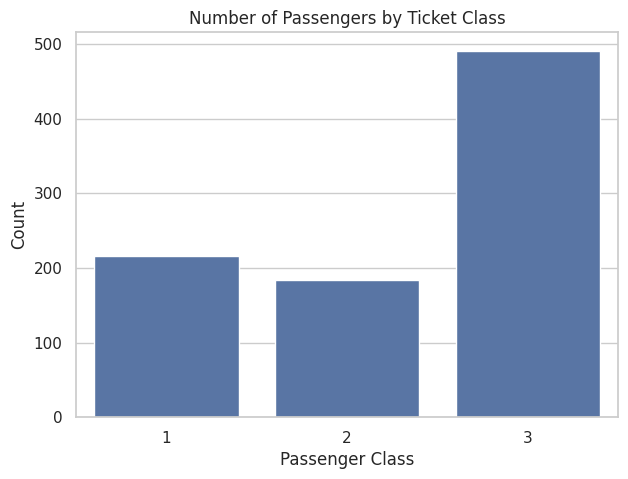

In [5]:

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Pclass")
plt.title("Number of Passengers by Ticket Class")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()


**Interpretation:** This graph compares the number of passengers in first, second, and third class. The tallest bar represents the class with the most passengers.

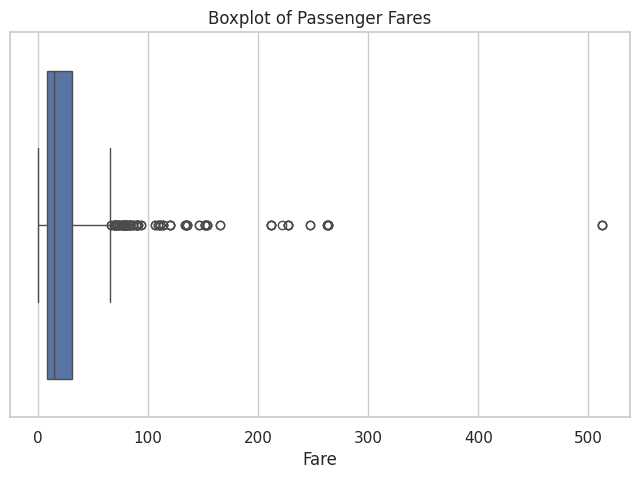

In [6]:

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Fare"])
plt.title("Boxplot of Passenger Fares")
plt.xlabel("Fare")
plt.show()


**Interpretation:** The boxplot shows the median, quartiles, spread, and potential outliers in passenger fares. Points beyond the whiskers may represent unusually high or low fares.

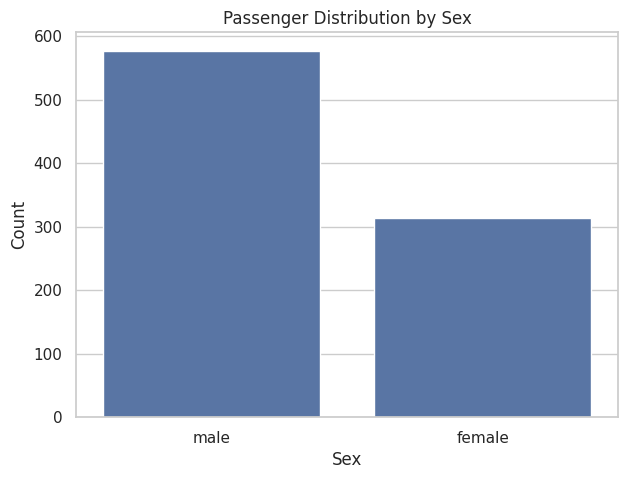

In [7]:

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Sex")
plt.title("Passenger Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()


**Interpretation:** This graph compares the number of male and female passengers.

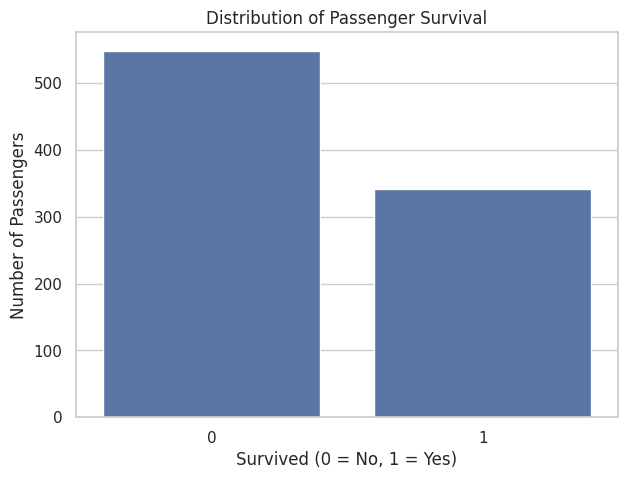

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


In [8]:

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Survived")
plt.title("Distribution of Passenger Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

print("Survival counts:")
print(df["Survived"].value_counts())

print("\nSurvival percentages:")
print((df["Survived"].value_counts(normalize=True) * 100).round(2))


**Interpretation**

The target variable has two classes: survived (1) and did not survive (0). More passengers did not survive than survived. Therefore, the target classes are not equally distributed.

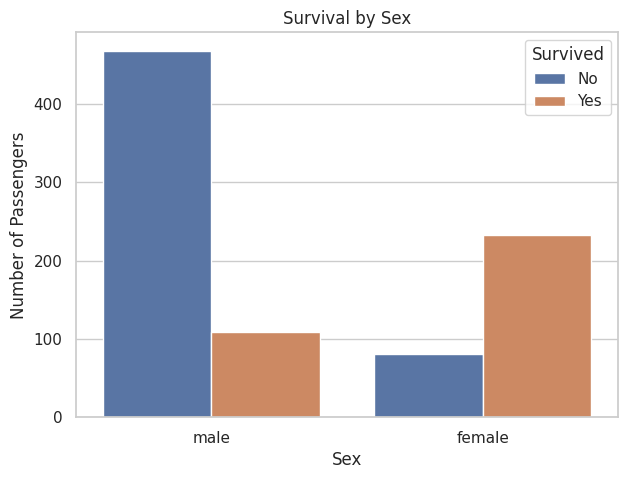

In [9]:

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Sex", hue="Survived")
plt.title("Survival by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()


**Interpretation:** The graph compares survival outcomes for male and female passengers. Female passengers had a higher survival rate than male passengers in the Titanic dataset.

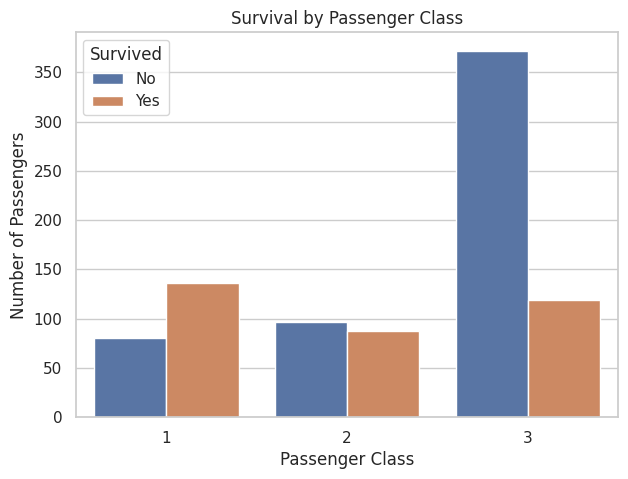

In [10]:

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Pclass", hue="Survived")
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()


**Interpretation:** Survival outcomes differed across passenger classes. First-class passengers generally had better survival outcomes than third-class passengers.

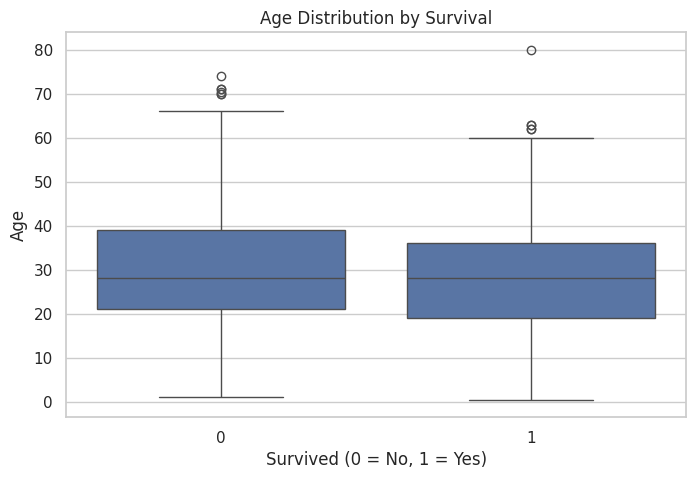

In [11]:

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Survived", y="Age")
plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.show()


**Interpretation:** The boxplot compares the age distributions of passengers who survived and those who did not. It helps identify differences in median age, spread, and potential outliers between the two groups.

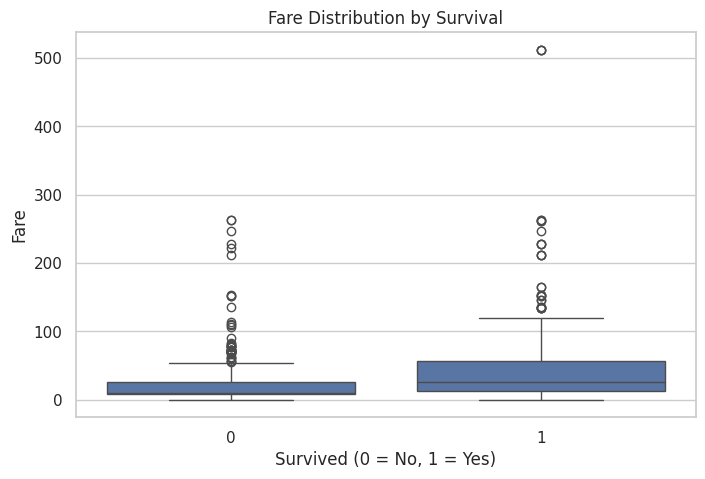

In [12]:

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Survived", y="Fare")
plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")
plt.show()


**Interpretation:** The boxplot compares ticket fares for survivors and non-survivors. Differences in the median and spread may suggest that ticket fare was associated with survival.

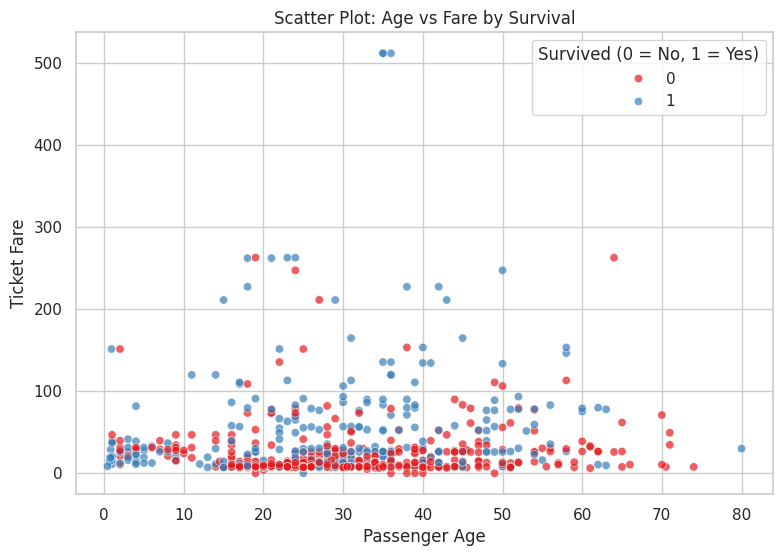

In [13]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Fare",
    hue="Survived",
    palette="Set1",
    alpha=0.7
)

plt.title("Scatter Plot: Age vs Fare by Survival")
plt.xlabel("Passenger Age")
plt.ylabel("Ticket Fare")
plt.legend(title="Survived (0 = No, 1 = Yes)")
plt.show()


**Interpretation**

The scatter plot shows the relationship between passenger age and ticket fare. Each point represents a passenger. The colors indicate whether the passenger survived or did not survive. The points are spread across different ages and fares, and some passengers paid much higher fares than others. The plot helps us explore possible patterns between age, fare, and survival.

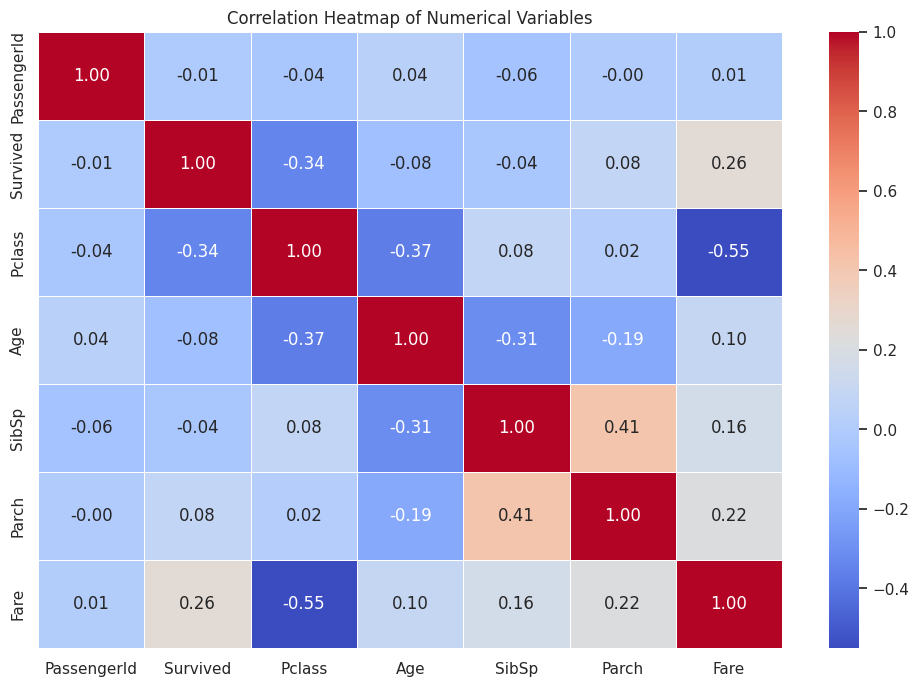

In [14]:

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation between numerical variables
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()


In [15]:

# Get unique pairs of correlations
corr_pairs = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
).stack()

# Strongest positive correlations
print("Top positive correlations:")
print(corr_pairs.sort_values(ascending=False).head(5))

# Strongest negative correlations
print("\nTop negative correlations:")
print(corr_pairs.sort_values().head(5))


Top positive correlations:
SibSp     Parch    0.414838
Survived  Fare     0.257307
Parch     Fare     0.216225
SibSp     Fare     0.159651
Age       Fare     0.096067
dtype: float64

Top negative correlations:
Pclass    Fare     -0.549500
          Age      -0.369226
Survived  Pclass   -0.338481
Age       SibSp    -0.308247
          Parch    -0.189119
dtype: float64


**Correlation Analysis**

The correlation heatmap shows the relationships between numerical variables in the Titanic dataset. Positive correlation means that two variables tend to increase together, while negative correlation means that one tends to decrease as the other increases. Correlations close to zero indicate weak linear relationships.

Passenger class (Pclass) and fare generally have a negative correlation because smaller class numbers represent higher passenger classes, which often have higher fares. The correlation between survival and other numerical variables helps us explore which features may be useful for future prediction.

Correlation does not necessarily mean causation.

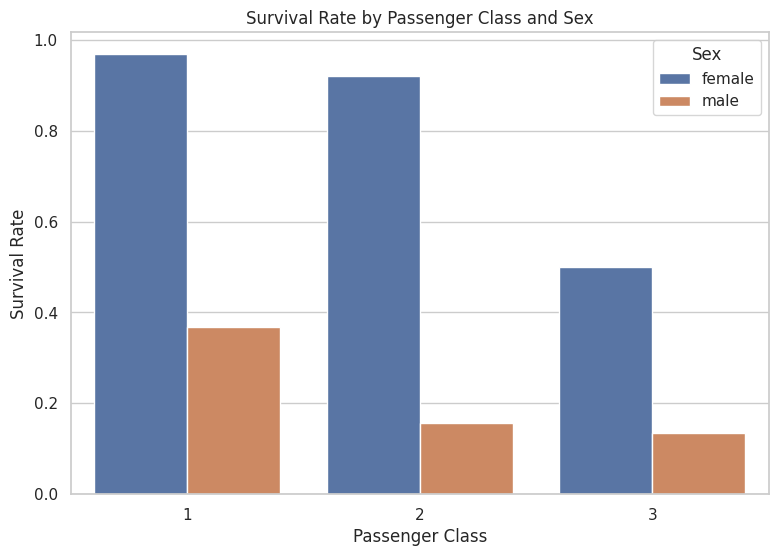

In [16]:

plt.figure(figsize=(9, 6))

sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    hue="Sex",
    errorbar=None
)

plt.title("Survival Rate by Passenger Class and Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()


**Interpretation**

This graph compares passenger survival rates by sex and passenger class. It helps us understand how survival differed between male and female passengers in different classes. Female passengers generally had higher survival rates than male passengers, and survival rates also varied by passenger class.

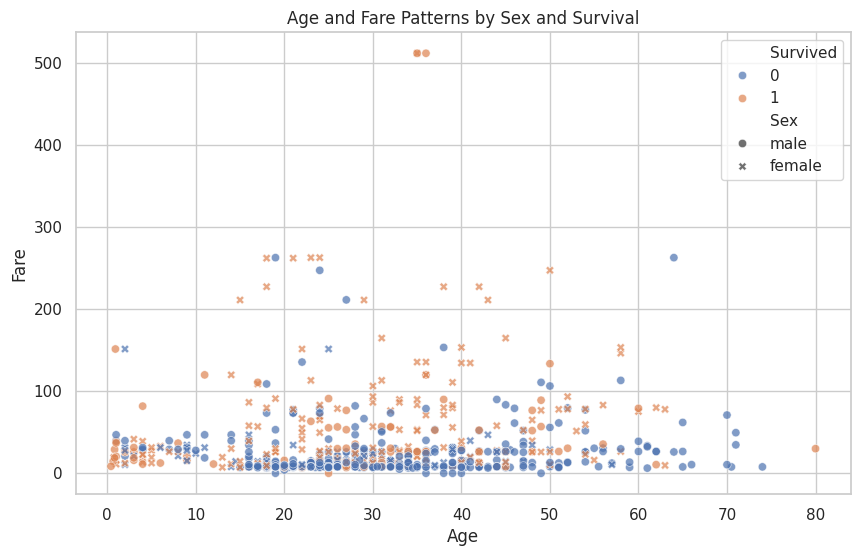

In [17]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Fare",
    hue="Survived",
    style="Sex",
    alpha=0.7
)

plt.title("Age and Fare Patterns by Sex and Survival")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()


**Interpretation**

This scatter plot compares age and fare while using color for survival status and marker style for sex. It helps us explore whether survival patterns differ across passenger ages, fares, and sex. Some passengers paid much higher fares than others, and the survival outcomes overlap across different groups.

Missing values:
Age         177
Cabin       687
Embarked      2
dtype: int64


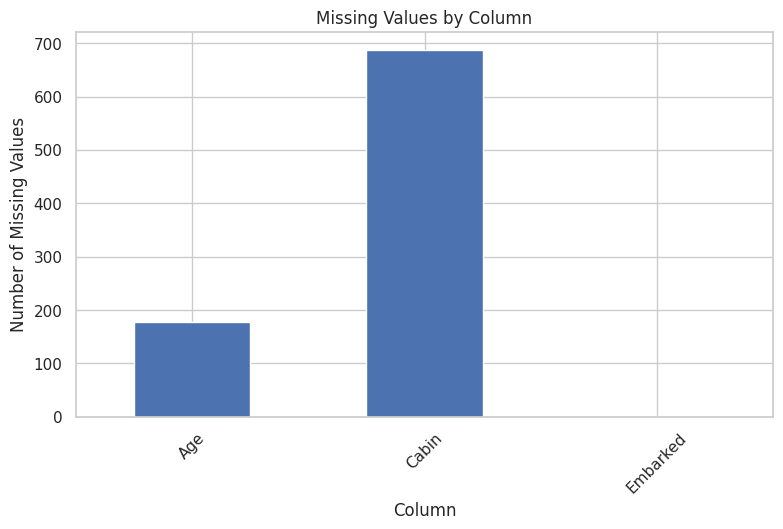

In [18]:

missing = df.isnull().sum()

print("Missing values:")
print(missing[missing > 0])

plt.figure(figsize=(9, 5))
missing[missing > 0].plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.show()


**Interpretation**

The analysis identifies columns with missing data. Age has missing values, Cabin has many missing values, and Embarked has a small number of missing values. These gaps may need to be handled before building a machine learning model.

Possible fare outliers: 116


,Pclass,Sex,Age,Fare,Survived
1,1,female,38.0,71.2833,1
27,1,male,19.0,263.0000,0
31,1,female,NaN,146.5208,1
34,1,male,28.0,82.1708,0
52,1,female,49.0,76.7292,1
61,1,female,38.0,80.0000,1
62,1,male,45.0,83.4750,0
72,2,male,21.0,73.5000,0
88,1,female,23.0,263.0000,1
102,1,male,21.0,77.2875,0


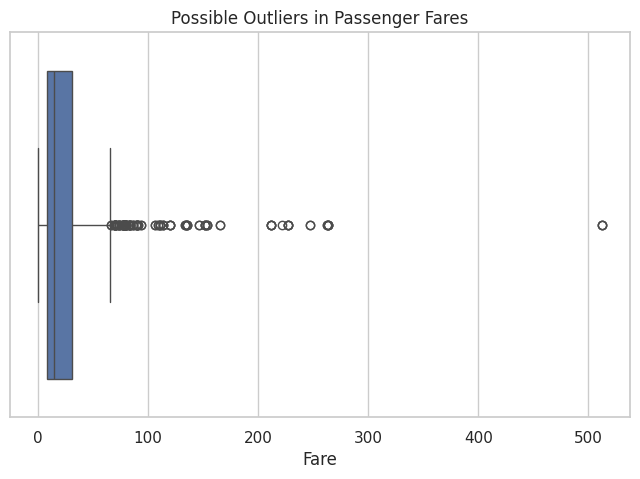

In [19]:

Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Fare"] < lower) | (df["Fare"] > upper)]

print("Possible fare outliers:", len(outliers))
display(outliers[["Pclass", "Sex", "Age", "Fare", "Survived"]].head(10))

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Fare"])
plt.title("Possible Outliers in Passenger Fares")
plt.xlabel("Fare")
plt.show()


**Interpretation**

The IQR method identifies possible outliers in passenger fares. Some passengers paid much higher fares than most other passengers. These values may represent expensive tickets or shared tickets rather than errors, so they should be investigated before removing them.

# 11. Final Findings

Based on the Exploratory Data Analysis of the Titanic dataset, the following findings were observed:

1. The dataset contains passenger information such as age, sex, passenger class, fare, and survival status.

2. More passengers did not survive than survived, showing that the target variable is imbalanced.

3. Female passengers had a higher survival rate than male passengers.

4. Passenger class was associated with survival. First-class passengers generally had better survival outcomes than third-class passengers.

5. The age distribution showed that passengers belonged to different age groups, and some age values were missing.

6. Ticket fares were unevenly distributed, with some unusually high fare values.

7. The correlation heatmap showed relationships between numerical variables. Passenger class and fare generally had a negative correlation.

8. These findings can help in future machine learning by identifying useful features, missing values, possible outliers, and class imbalance that may require preprocessing.

# Conclusion

Exploratory Data Analysis helped us understand the Titanic dataset through statistical summaries and visualizations. The analysis revealed patterns in passenger survival, relationships between variables, missing data, and possible outliers. These findings can guide data preprocessing and help develop a machine learning model to predict passenger survival.